# 02 – Preprocessing, Models, Tuning and Evaluation (Task 2 + ethics checks for Task 3)

We build three classifiers required by the brief and compare them fairly:

| Model | One-line idea | Week |
|---|---|---|
| **K-Nearest Neighbours (KNN)** | a customer is labelled like the *K* most similar customers | 5 |
| **Logistic Regression** | weighted sum of features → sigmoid → probability of churn | 3 |
| **Random Forest** | many decision trees on random samples/features vote | 4–5 |

Two **experimental settings** are run for every model:
- **Setting A – Baseline:** scikit-learn default hyperparameters, no imbalance handling.
- **Setting B – Tuned:** hyperparameters (and an imbalance strategy) chosen by `GridSearchCV` with 5-fold stratified cross-validation, optimising **F1**.

**Golden rule:** the test set is locked away and used **once**, at the end, for the final numbers. Every choice is made with cross-validation on the training set.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             RocCurveDisplay, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline   # a Pipeline that allows a resampling step
from imblearn.over_sampling import SMOTE

sys.path.insert(0, "..")
from src.data_prep import load_clean_data, NUMERIC_COLS, TARGET, categorical_columns

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="Set2")
FIG_DIR = Path("../figures"); FIG_DIR.mkdir(exist_ok=True)
RES_DIR = Path("../results"); RES_DIR.mkdir(exist_ok=True)
SEED = 42            # fixed random seed -> every run gives the same numbers (reproducibility)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## 1. Load the cleaned data and split it

In [2]:
df = load_clean_data("../data/Telco-Customer-Churn.csv")   # same cleaning as the EDA notebook
X = df.drop(columns=TARGET)
y = df[TARGET]

num_cols = NUMERIC_COLS                  # tenure, MonthlyCharges, TotalCharges, NumServices
cat_cols = categorical_columns(df)       # the 16 text columns
print(f"{len(num_cols)} numeric:", num_cols)
print(f"{len(cat_cols)} categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

print("\nTrain:", X_train.shape, " Test:", X_test.shape)
print(f"Churn rate  train {y_train.mean():.3f} | test {y_test.mean():.3f} | full {y.mean():.3f}")

4 numeric: ['tenure', 'MonthlyCharges', 'TotalCharges', 'NumServices']
16 categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Train: (5634, 20)  Test: (1409, 20)
Churn rate  train 0.265 | test 0.265 | full 0.265


**Why stratify?** `stratify=y` keeps the churn rate (≈ 26.5%) identical in the training and test sets.
Without it, a random split could put noticeably more or fewer churners in the test set and make the score luckier or unluckier than it should be.

**Why 80/20?** 5,634 rows to learn from and 1,409 unseen rows for an honest final score.

## 2. Preprocessing pipeline

Models need numbers on comparable scales:
- **Numeric columns → `StandardScaler`**: z = (x − mean) / std, so every numeric column has mean 0 and std 1.
  KNN uses distances and Logistic Regression uses regularised weights – both are distorted if one column is in the thousands.
- **Text columns → `OneHotEncoder`**: one 0/1 column per category (e.g. `Contract_Two year`). We do **not** use label encoding
  (0, 1, 2) because categories like payment method have no order, and KNN/LogReg would wrongly treat "2" as bigger than "1".
  `drop="if_binary"` keeps one column for yes/no features (a second column would be redundant).

The `ColumnTransformer` + `Pipeline` combination is the key **anti-leakage** tool: when the pipeline is fitted, the scaler learns
the mean/std **from the training folds only**, and inside cross-validation it is re-fitted in every fold.
Random Forest does not need scaling (trees split on one feature at a time), but scaling does not change a tree, so using one
shared preprocessor keeps the comparison simple and fair.

In [3]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
])

# Peek at what the models will actually receive
Xt = preprocessor.fit(X_train).transform(X_train)
feature_names = preprocessor.get_feature_names_out()
print("Shape after preprocessing:", Xt.shape)
print(list(feature_names))

Shape after preprocessing: (5634, 27)
['num__tenure', 'num__MonthlyCharges', 'num__TotalCharges', 'num__NumServices', 'cat__gender_Male', 'cat__SeniorCitizen_Yes', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__PhoneService_Yes', 'cat__MultipleLines_Yes', 'cat__InternetService_DSL', 'cat__InternetService_Fiber optic', 'cat__InternetService_No', 'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_Yes', 'cat__DeviceProtection_Yes', 'cat__TechSupport_Yes', 'cat__StreamingTV_Yes', 'cat__StreamingMovies_Yes', 'cat__Contract_Month-to-month', 'cat__Contract_One year', 'cat__Contract_Two year', 'cat__PaperlessBilling_Yes', 'cat__PaymentMethod_Bank transfer (automatic)', 'cat__PaymentMethod_Credit card (automatic)', 'cat__PaymentMethod_Electronic check', 'cat__PaymentMethod_Mailed check']


## 3. Evaluation set-up

**Positive class = churn (1).** From the confusion matrix:
- **Precision** = TP / (TP + FP): of the customers we flag, how many really churn? (wasted retention offers)
- **Recall** = TP / (TP + FN): of the real churners, how many do we catch? (lost customers)
- **F1** = 2·P·R / (P + R): balance of the two. **This is our main metric** – it focuses on the churn class and is not fooled by imbalance.
- **ROC-AUC**: probability that a random churner gets a higher churn score than a random non-churner (0.5 = random, 1 = perfect). Threshold-free, good for ranking models.
- **Accuracy** is reported for completeness but can mislead (73.5% for "never churn").

**Cross-validation:** `StratifiedKFold(5)` splits the training set into 5 folds; the model trains on 4 and is scored on the 5th, five times.
We report the **mean ± standard deviation**, so we can see whether differences between models are bigger than the noise.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {"f1": "f1", "recall": "recall", "precision": "precision", "roc_auc": "roc_auc", "accuracy": "accuracy"}

def test_metrics(model, name, setting):
    """Score a fitted model ONCE on the held-out test set."""
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    return {"model": name, "setting": setting,
            "accuracy": accuracy_score(y_test, pred), "precision": precision_score(y_test, pred),
            "recall": recall_score(y_test, pred), "f1": f1_score(y_test, pred),
            "roc_auc": roc_auc_score(y_test, proba)}

cv_rows, test_rows, fitted = [], [], {}

## 4. Setting A – Baseline models (default hyperparameters)

Defaults: KNN with K = 5, Logistic Regression with C = 1, Random Forest with 100 fully-grown trees. No imbalance handling.

In [5]:
baseline_models = {
    "KNN": KNeighborsClassifier(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=SEED, n_jobs=-1),
}

for name, clf in baseline_models.items():
    pipe = Pipeline([("pre", preprocessor), ("clf", clf)])
    cvres = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING, return_train_score=True)
    row = {"model": name, "setting": "A: baseline"}
    for m in SCORING:
        row[f"cv_{m}"] = cvres[f"test_{m}"].mean()
        row[f"cv_{m}_std"] = cvres[f"test_{m}"].std()
    row["train_f1"] = cvres["train_f1"].mean()
    cv_rows.append(row)

    pipe.fit(X_train, y_train)                       # refit on the whole training set
    fitted[(name, "A: baseline")] = pipe
    test_rows.append(test_metrics(pipe, name, "A: baseline"))

pd.DataFrame(cv_rows)[["model", "train_f1", "cv_f1", "cv_f1_std", "cv_recall", "cv_precision", "cv_roc_auc", "cv_accuracy"]].round(3)

,model,train_f1,cv_f1,cv_f1_std,cv_recall,cv_precision,cv_roc_auc,cv_accuracy
0,KNN,0.680,0.544,0.016,0.526,0.564,0.778,0.766
1,Logistic Regression,0.602,0.593,0.031,0.544,0.654,0.846,0.803
2,Random Forest,0.997,0.548,0.028,0.484,0.632,0.826,0.788


**Reading the baseline:**
- All three reach ~0.75–0.80 accuracy but **recall is only around 0.5**: with no imbalance handling the models miss about half of the churners,
  because predicting "stay" is right most of the time.
- **Random Forest's training F1 is ≈ 1.0 but its CV F1 is far lower** – the classic sign of **overfitting**: fully-grown trees memorise the training data.
  KNN with K = 5 shows the same gap on a smaller scale. Logistic Regression's train and CV scores are close (a simple, low-variance model).

Tuning should fix both problems: control model complexity and handle the imbalance.

## 5. Setting B – Hyperparameter tuning with GridSearchCV

`GridSearchCV` tries **every combination** in a grid, scores each with 5-fold CV on the training set, and refits the best one on all training data.
We optimise **F1** (`refit="f1"`). The grids, and why:

| Model | Hyperparameters searched | Why these |
|---|---|---|
| KNN | `n_neighbors` 5–51 (odd), `weights` uniform/distance, `p` 1 (Manhattan) / 2 (Euclidean), resampling none / **SMOTE** | small K overfits (noisy), large K underfits; odd K avoids ties; KNN has no `class_weight`, so SMOTE is its imbalance tool |
| Logistic Regression | `C` 0.001–100, `penalty` L1/L2, `class_weight` None/balanced | `C` = 1/regularisation strength (small C = simpler model); L1 can switch useless features off |
| Random Forest | `n_estimators` 200/400, `max_depth` 6/10/15/None, `min_samples_leaf` 1/5/10, `max_features` sqrt/0.5, `class_weight` None/balanced | depth and leaf size control overfitting; `max_features` controls how different the trees are |

**SMOTE** creates synthetic churners by interpolating between a churner and its nearest churner neighbours. It sits *inside* the pipeline,
so it only ever touches the training folds – the validation fold and the test set keep their real 26.5% churn rate.
**`class_weight="balanced"`** instead makes each misclassified churner cost ≈ 2.8× more in training.

In [6]:
search_space = {
    "KNN": (
        ImbPipeline([("pre", preprocessor), ("sampler", "passthrough"), ("clf", KNeighborsClassifier())]),
        {"sampler": ["passthrough", SMOTE(random_state=SEED)],
         "clf__n_neighbors": [5, 11, 15, 21, 31, 41, 51],
         "clf__weights": ["uniform", "distance"],
         "clf__p": [1, 2]}),
    "Logistic Regression": (
        Pipeline([("pre", preprocessor), ("clf", LogisticRegression(solver="liblinear", max_iter=2000))]),
        {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
         "clf__penalty": ["l1", "l2"],
         "clf__class_weight": [None, "balanced"]}),
    "Random Forest": (
        Pipeline([("pre", preprocessor), ("clf", RandomForestClassifier(random_state=SEED, n_jobs=1))]),
        {"clf__n_estimators": [200, 400],
         "clf__max_depth": [6, 10, 15, None],
         "clf__min_samples_leaf": [1, 5, 10],
         "clf__max_features": ["sqrt", 0.5],
         "clf__class_weight": [None, "balanced"]}),
}

searches = {}
for name, (pipe, grid) in search_space.items():
    n_combos = int(np.prod([len(v) for v in grid.values()]))
    t0 = time.time()
    gs = GridSearchCV(pipe, grid, scoring=SCORING, refit="f1", cv=cv, n_jobs=-1, return_train_score=True)
    gs.fit(X_train, y_train)
    searches[name] = gs
    print(f"{name}: {n_combos} combinations x 5 folds = {n_combos * 5} fits in {time.time() - t0:.0f}s")
    print("   best params:", {k: (type(v).__name__ if hasattr(v, "fit_resample") else v) for k, v in gs.best_params_.items()})
    print(f"   best CV F1: {gs.best_score_:.3f}")

    i = gs.best_index_
    res = gs.cv_results_
    row = {"model": name, "setting": "B: tuned"}
    for m in SCORING:
        row[f"cv_{m}"] = res[f"mean_test_{m}"][i]
        row[f"cv_{m}_std"] = res[f"std_test_{m}"][i]
    row["train_f1"] = res["mean_train_f1"][i]
    cv_rows.append(row)
    fitted[(name, "B: tuned")] = gs.best_estimator_
    test_rows.append(test_metrics(gs.best_estimator_, name, "B: tuned"))

KNN: 56 combinations x 5 folds = 280 fits in 114s
   best params: {'clf__n_neighbors': 41, 'clf__p': 1, 'clf__weights': 'uniform', 'sampler': 'SMOTE'}
   best CV F1: 0.616


Logistic Regression: 24 combinations x 5 folds = 120 fits in 24s
   best params: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__penalty': 'l2'}
   best CV F1: 0.631


Random Forest: 96 combinations x 5 folds = 480 fits in 733s
   best params: {'clf__class_weight': 'balanced', 'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5, 'clf__n_estimators': 400}
   best CV F1: 0.637


### 5.1 How each hyperparameter changes the CV score

Each plot varies one hyperparameter while the others stay at their best values. Training F1 is shown too, so the **gap between
the training and validation curves shows overfitting**.

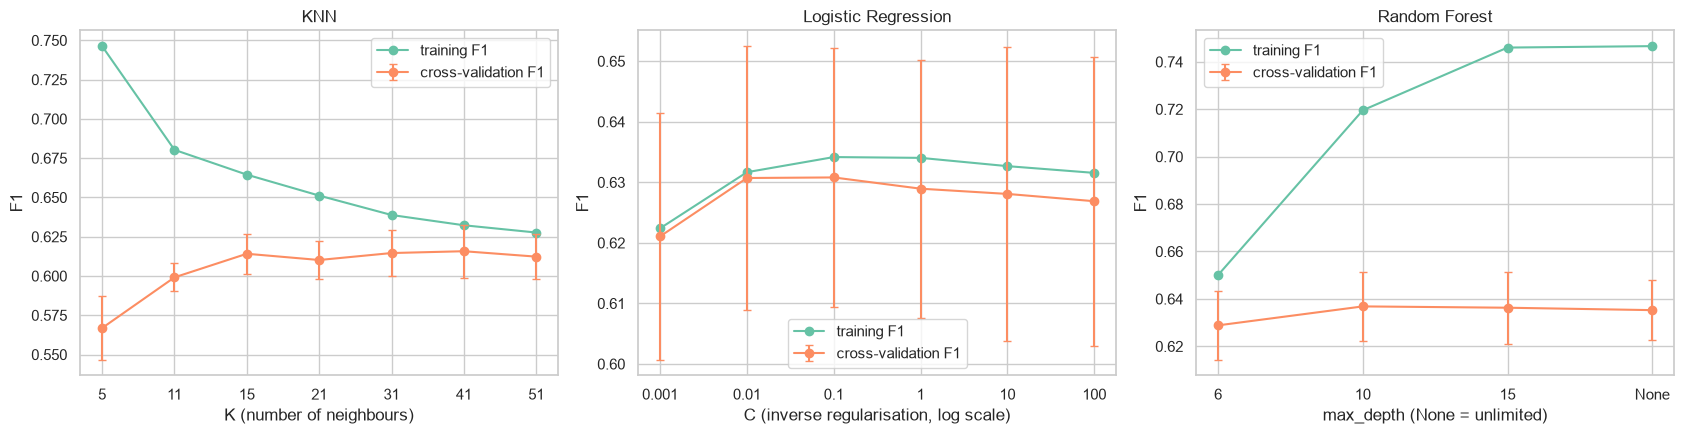

In [7]:
def same(a, b):
    """Compare two hyperparameter values (handles 1 vs 1.0, None, and estimator objects)."""
    try:
        if a == b:
            return True
    except Exception:
        pass
    try:
        return float(a) == float(b)
    except (TypeError, ValueError):
        return str(a) == str(b)

def curve(gs, param, values):
    """Train/CV F1 when `param` varies and all other params stay at their best values."""
    res = pd.DataFrame(gs.cv_results_)
    mask = np.ones(len(res), dtype=bool)
    for k, v in gs.best_params_.items():
        if k != param:
            mask &= res[f"param_{k}"].map(lambda a: same(a, v)).to_numpy(dtype=bool)
    sub = res[mask]
    rows = [sub[sub[f"param_{param}"].map(lambda a: same(a, v)).to_numpy(dtype=bool)].iloc[0] for v in values]
    out = pd.DataFrame(rows)[["mean_train_f1", "mean_test_f1", "std_test_f1"]]
    out.index = [str(v) for v in values]
    return out

panels = [("KNN", "clf__n_neighbors", "K (number of neighbours)"),
          ("Logistic Regression", "clf__C", "C (inverse regularisation, log scale)"),
          ("Random Forest", "clf__max_depth", "max_depth (None = unlimited)")]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, param, label) in zip(axes, panels):
    values = search_space[name][1][param]
    c = curve(searches[name], param, values)
    x = np.arange(len(c))
    ax.plot(x, c["mean_train_f1"], marker="o", label="training F1")
    ax.errorbar(x, c["mean_test_f1"], yerr=c["std_test_f1"], marker="o", capsize=3, label="cross-validation F1")
    ax.set_xticks(x, c.index); ax.set(title=name, xlabel=label, ylabel="F1"); ax.legend()
save("11_tuning_curves")

**Reading the curves (bias–variance trade-off, Weeks 2 & 8):**
- **KNN:** K = 5 is close to memorising (big train/CV gap = high *variance*). As K grows, the gap closes and CV F1 improves until it levels off –
  each prediction is averaged over more neighbours, so it is less noisy.
- **Logistic Regression:** the smallest C (0.001, strongest regularisation) scores lowest because the weights are squeezed towards zero
  (more *bias*); from C ≈ 0.01 upwards the curve is flat and the train and CV lines almost touch – a simple, low-variance model.
  The differences are smaller than the fold-to-fold error bars, so LR is not sensitive to C here.
- **Random Forest** (with the best `min_samples_leaf = 5`): training F1 keeps rising with depth (0.65 → 0.75) while CV F1 stays flat at ≈ 0.63–0.64,
  so extra depth only adds variance. The baseline forest (unlimited depth *and* leaves of size 1) reached a training F1 of 0.997 with CV F1 0.548 –
  limiting depth and leaf size acts like **pruning**.

## 6. Results – both experimental settings

In [8]:
cv_table = pd.DataFrame(cv_rows)
cv_table["cv_f1 (mean ± std)"] = cv_table.apply(lambda r: f"{r.cv_f1:.3f} ± {r.cv_f1_std:.3f}", axis=1)
cv_table["train-CV F1 gap"] = cv_table["train_f1"] - cv_table["cv_f1"]
cv_view = cv_table[["model", "setting", "train_f1", "cv_f1 (mean ± std)", "train-CV F1 gap", "cv_recall", "cv_precision", "cv_roc_auc", "cv_accuracy"]]
cv_view.to_csv(RES_DIR / "cv_results.csv", index=False)
print("Cross-validation on the TRAINING set (5 folds)")
cv_view.round(3)

Cross-validation on the TRAINING set (5 folds)


,model,setting,train_f1,cv_f1 (mean ± std),train-CV F1 gap,cv_recall,cv_precision,cv_roc_auc,cv_accuracy
0,KNN,A: baseline,0.680,0.544 ± 0.016,0.136,0.526,0.564,0.778,0.766
1,Logistic Regression,A: baseline,0.602,0.593 ± 0.031,0.009,0.544,0.654,0.846,0.803
2,Random Forest,A: baseline,0.997,0.548 ± 0.028,0.449,0.484,0.632,0.826,0.788
3,KNN,B: tuned,0.632,0.616 ± 0.017,0.017,0.819,0.494,0.834,0.729
4,Logistic Regression,B: tuned,0.634,0.631 ± 0.021,0.003,0.799,0.521,0.845,0.752
5,Random Forest,B: tuned,0.720,0.637 ± 0.015,0.083,0.779,0.539,0.847,0.764


In [9]:
test_table = pd.DataFrame(test_rows).sort_values(["setting", "model"])
test_table.to_csv(RES_DIR / "test_results.csv", index=False)
print("Final scores on the untouched TEST set (1,409 customers)")
test_table.round(3)

Final scores on the untouched TEST set (1,409 customers)


,model,setting,accuracy,precision,recall,f1,roc_auc
0,KNN,A: baseline,0.764,0.557,0.537,0.547,0.786
1,Logistic Regression,A: baseline,0.804,0.654,0.556,0.601,0.842
2,Random Forest,A: baseline,0.789,0.631,0.489,0.551,0.820
3,KNN,B: tuned,0.727,0.492,0.832,0.618,0.828
4,Logistic Regression,B: tuned,0.740,0.507,0.786,0.616,0.841
5,Random Forest,B: tuned,0.759,0.531,0.794,0.637,0.844


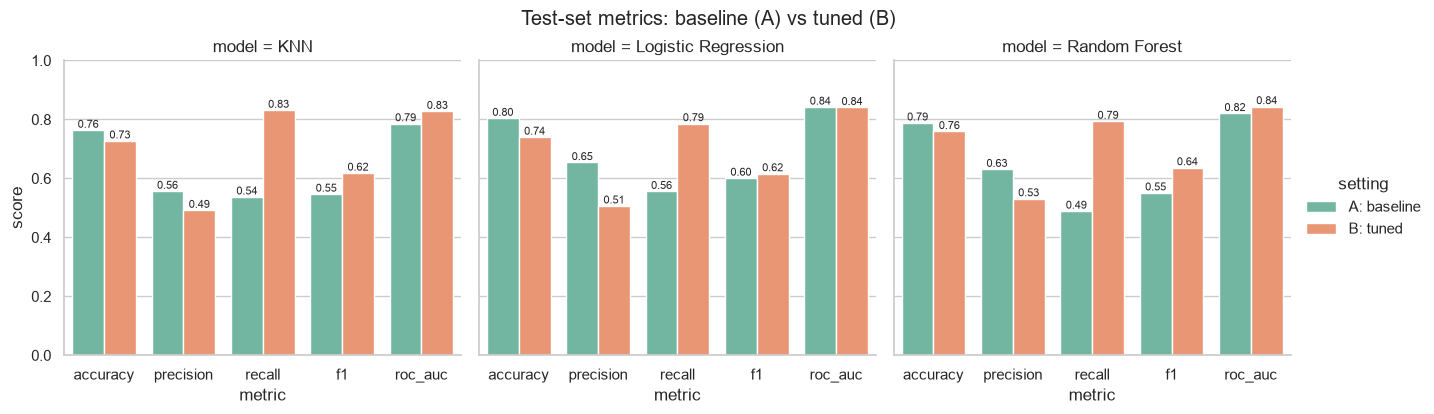

In [10]:
plot_df = test_table.melt(id_vars=["model", "setting"], value_vars=["accuracy", "precision", "recall", "f1", "roc_auc"],
                          var_name="metric", value_name="score")
g = sns.catplot(data=plot_df, x="metric", y="score", hue="setting", col="model", kind="bar", height=4, aspect=1.1)
g.set(ylim=(0, 1))
for ax in g.axes.flat:
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8)
g.fig.suptitle("Test-set metrics: baseline (A) vs tuned (B)", y=1.03)
plt.savefig(FIG_DIR / "12_baseline_vs_tuned.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Confusion matrices (tuned models)

Rows = actual class, columns = predicted class (scikit-learn convention).
Top-left = TN (loyal, left alone) · top-right = FP (false alarm) · bottom-left = FN (**missed churner**) · bottom-right = TP (churner caught).

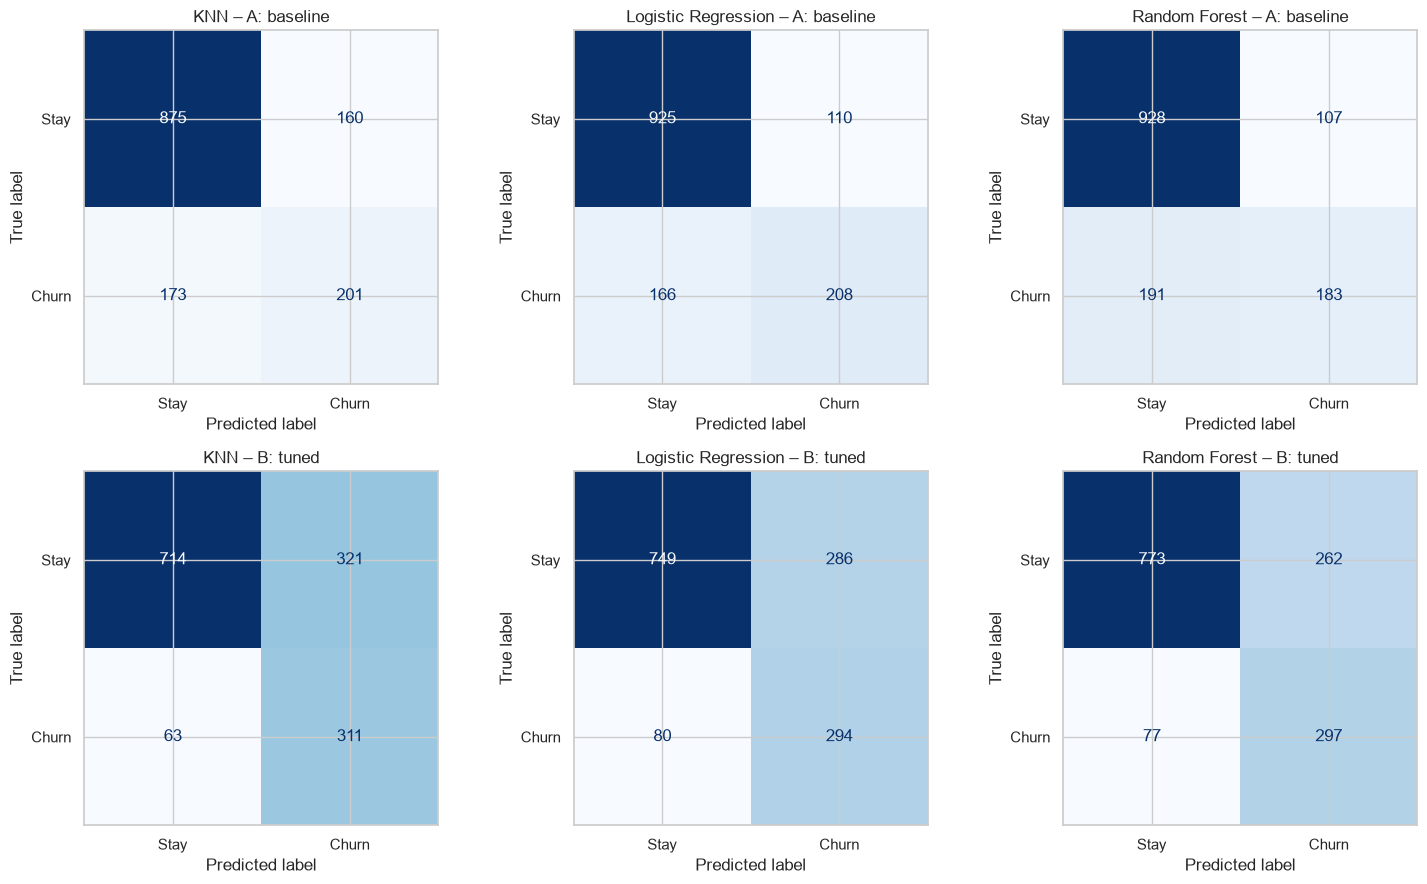

===== KNN (tuned) =====


              precision    recall  f1-score   support

        Stay      0.919     0.690     0.788      1035
       Churn      0.492     0.832     0.618       374

    accuracy                          0.727      1409
   macro avg      0.706     0.761     0.703      1409
weighted avg      0.806     0.727     0.743      1409

===== Logistic Regression (tuned) =====
              precision    recall  f1-score   support

        Stay      0.903     0.724     0.804      1035
       Churn      0.507     0.786     0.616       374

    accuracy                          0.740      1409
   macro avg      0.705     0.755     0.710      1409
weighted avg      0.798     0.740     0.754      1409

===== Random Forest (tuned) =====


              precision    recall  f1-score   support

        Stay      0.909     0.747     0.820      1035
       Churn      0.531     0.794     0.637       374

    accuracy                          0.759      1409
   macro avg      0.720     0.770     0.728      1409
weighted avg      0.809     0.759     0.771      1409



In [11]:
names = list(search_space)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for r, setting in enumerate(["A: baseline", "B: tuned"]):
    for c, name in enumerate(names):
        model = fitted[(name, setting)]
        ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, display_labels=["Stay", "Churn"],
                                              cmap="Blues", colorbar=False, ax=axes[r, c])
        axes[r, c].set_title(f"{name} – {setting}")
save("13_confusion_matrices")

for name in names:
    print(f"===== {name} (tuned) =====")
    print(classification_report(y_test, fitted[(name, "B: tuned")].predict(X_test), target_names=["Stay", "Churn"], digits=3))

## 8. ROC and Precision–Recall curves (tuned models)

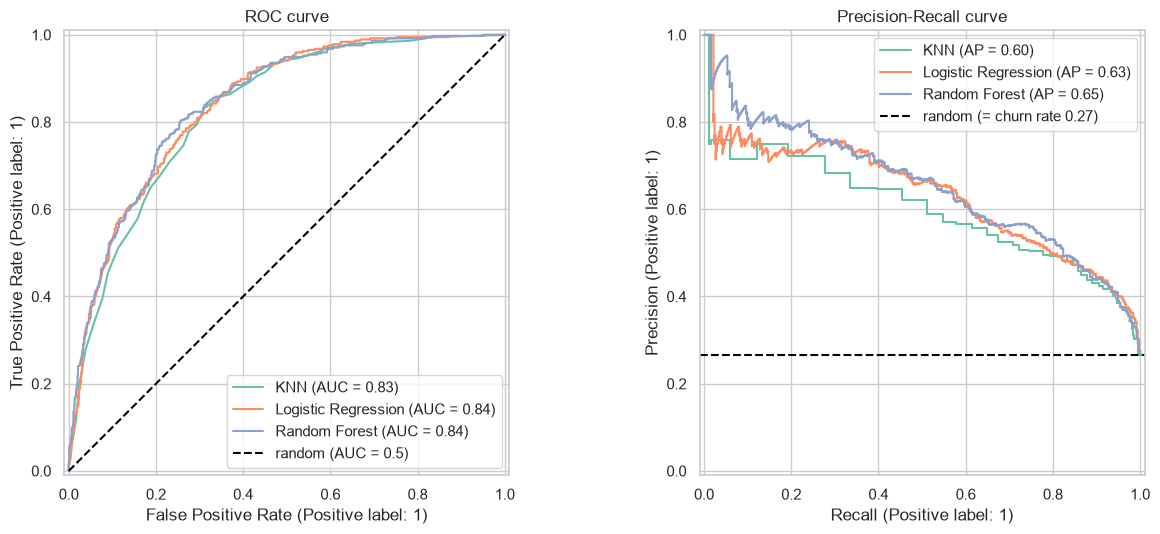

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for name in names:
    m = fitted[(name, "B: tuned")]
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", label="random (AUC = 0.5)"); axes[0].legend(); axes[0].set_title("ROC curve")
axes[1].axhline(y_test.mean(), ls="--", c="k", label=f"random (= churn rate {y_test.mean():.2f})"); axes[1].legend(); axes[1].set_title("Precision-Recall curve")
save("14_roc_pr_curves")

**Reading the curves:** each point on a curve is a different decision **threshold** (default 0.5). Moving the threshold down catches more churners
(higher recall, moving right on the PR curve) at the cost of more false alarms (lower precision). The area under the ROC curve summarises ranking quality
independently of the threshold – this is why AUC is good for *comparing* models, while precision/recall at a chosen threshold describe how the model would be *used*.

## 9. What drives the predictions? (explainability)

Three complementary views:
1. **Logistic Regression coefficients** – positive = pushes towards churn. Because numeric inputs are standardised, sizes are comparable.
2. **Random Forest impurity importance** – how much each feature reduces Gini impurity across all trees.
3. **Permutation importance** (model-agnostic) – shuffle one original column in the test set and measure how much F1 drops.

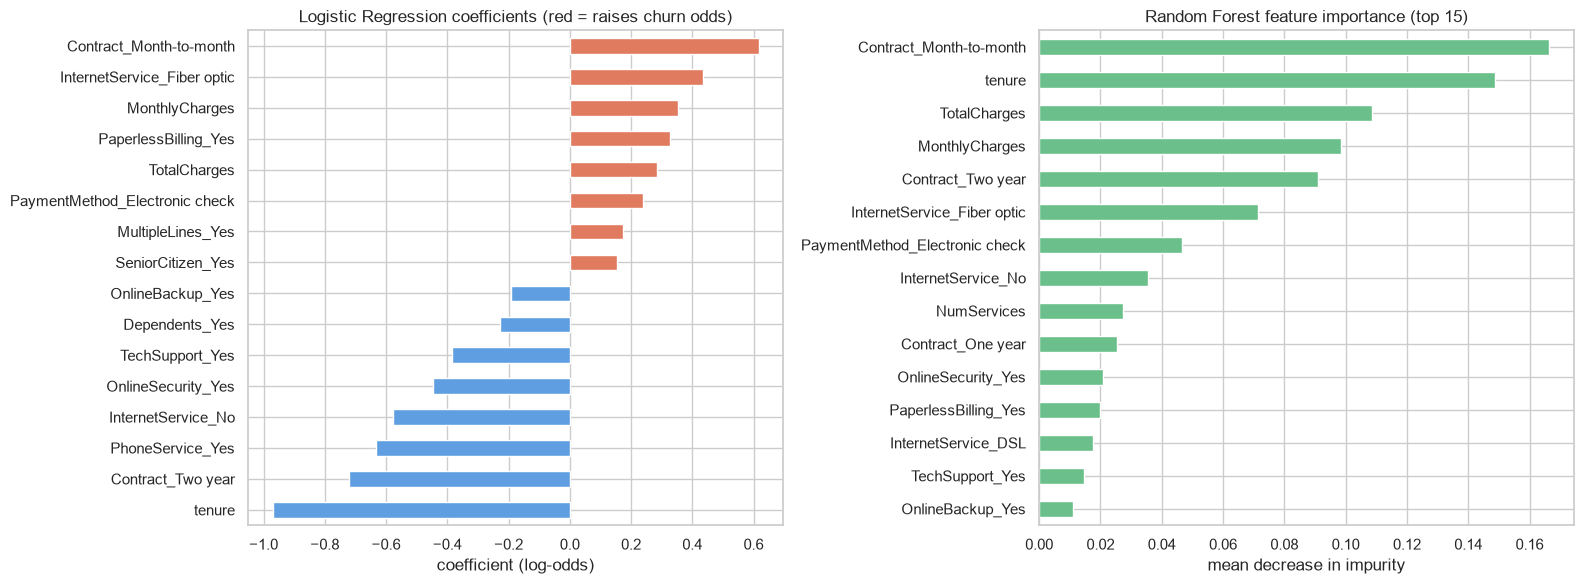

Odds ratios (e^coef) for the 5 strongest positive coefficients:
Contract_Month-to-month        1.85
InternetService_Fiber optic    1.54
MonthlyCharges                 1.42
PaperlessBilling_Yes           1.39
TotalCharges                   1.33
dtype: float64


In [13]:
lr = fitted[("Logistic Regression", "B: tuned")]
coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
coefs.index = coefs.index.str.replace(r"^(num|cat)__", "", regex=True)
top_coefs = pd.concat([coefs.nlargest(8), coefs.nsmallest(8)]).sort_values()

rf = fitted[("Random Forest", "B: tuned")]
rf_imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=rf.named_steps["pre"].get_feature_names_out())
rf_imp.index = rf_imp.index.str.replace(r"^(num|cat)__", "", regex=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top_coefs.plot(kind="barh", ax=axes[0], color=np.where(top_coefs > 0, "#e07b5f", "#5f9ee0"))
axes[0].set(title="Logistic Regression coefficients (red = raises churn odds)", xlabel="coefficient (log-odds)")
rf_imp.nlargest(15).sort_values().plot(kind="barh", ax=axes[1], color="#6bbf8a")
axes[1].set(title="Random Forest feature importance (top 15)", xlabel="mean decrease in impurity")
save("15_feature_importance")
print("Odds ratios (e^coef) for the 5 strongest positive coefficients:")
print(np.exp(coefs.nlargest(5)).round(2))

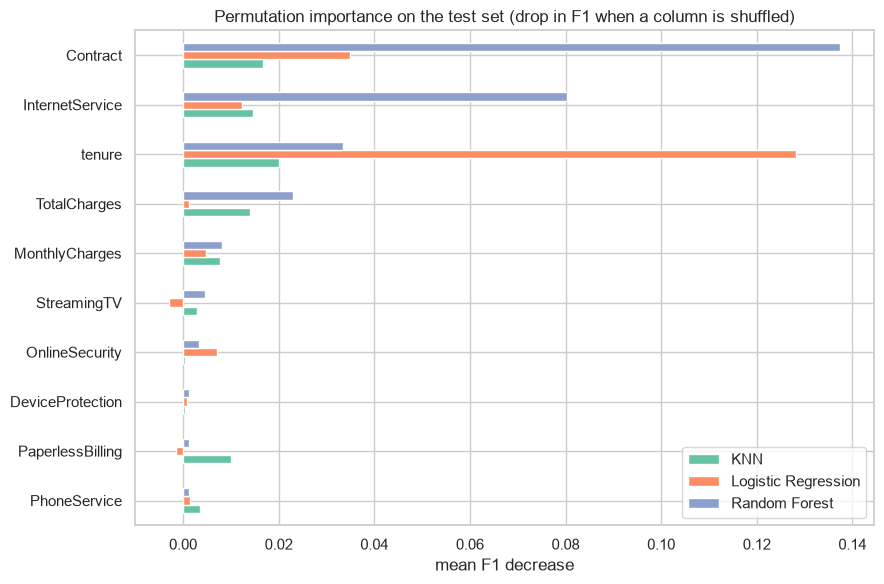

,KNN,Logistic Regression,Random Forest
Contract,0.017,0.035,0.137
InternetService,0.015,0.012,0.080
tenure,0.020,0.128,0.033
TotalCharges,0.014,0.001,0.023
MonthlyCharges,0.008,0.005,0.008
StreamingTV,0.003,-0.003,0.005
OnlineSecurity,0.000,0.007,0.003
DeviceProtection,0.000,0.001,0.001
PaperlessBilling,0.010,-0.001,0.001
PhoneService,0.004,0.002,0.001


In [14]:
perm_rows = {}
for name in names:
    pi = permutation_importance(fitted[(name, "B: tuned")], X_test, y_test, scoring="f1",
                                n_repeats=10, random_state=SEED, n_jobs=-1)
    perm_rows[name] = pd.Series(pi.importances_mean, index=X_test.columns)
perm = pd.DataFrame(perm_rows).sort_values("Random Forest", ascending=False)
perm.to_csv(RES_DIR / "permutation_importance.csv")

perm.head(10).iloc[::-1].plot(kind="barh", figsize=(9, 6))
plt.title("Permutation importance on the test set (drop in F1 when a column is shuffled)")
plt.xlabel("mean F1 decrease")
save("16_permutation_importance")
perm.head(10).round(3)

**Insight:** all three models agree with the EDA – **Contract, tenure and InternetService/charges** dominate. In Logistic Regression, the odds ratio
(e^coefficient) reads as "how many times the churn odds are multiplied". Long contracts and long tenure have strong negative coefficients (protect against churn);
fibre optic and electronic-check payment raise the odds. Features such as `gender` and `PhoneService` contribute almost nothing.
Because TotalCharges is strongly correlated with tenure (multicollinearity), the individual coefficients of those two should not be over-interpreted.

## 10. Error analysis – who do we miss?
Compare the churners the best model **catches** (TP) with the churners it **misses** (FN).

In [15]:
best_name = test_table[test_table.setting == "B: tuned"].sort_values("f1", ascending=False).iloc[0]["model"]
best = fitted[(best_name, "B: tuned")]
print("Best tuned model by test F1:", best_name)

res = X_test.copy()
res["actual"] = y_test.values
res["pred"] = best.predict(X_test)
churners = res[res.actual == 1].copy()
churners["outcome"] = np.where(churners.pred == 1, "caught (TP)", "missed (FN)")
summary = churners.groupby("outcome").agg(
    customers=("tenure", "size"), median_tenure=("tenure", "median"), median_monthly=("MonthlyCharges", "median"),
    month_to_month=("Contract", lambda s: (s == "Month-to-month").mean()),
    fibre=("InternetService", lambda s: (s == "Fiber optic").mean()),
    electronic_check=("PaymentMethod", lambda s: (s == "Electronic check").mean()))
summary.round(2)

Best tuned model by test F1: Random Forest


,customers,median_tenure,median_monthly,month_to_month,fibre,electronic_check
outcome,,,,,,
caught (TP),297,5.0,77.85,0.99,0.75,0.62
missed (FN),77,32.0,65.25,0.47,0.38,0.29


**Insight:** the missed churners look like *loyal* customers – longer tenure, cheaper plans and far more often on one/two-year contracts.
They leave for reasons the dataset does not record (moving house, a competitor offer, a bad support call). No tuning can recover that information;
it is a **data limitation**, discussed in the report.

## 11. Fairness check (input to Task 3 – AI ethics)

A model can be accurate overall but treat groups differently. For the sensitive attributes **gender** and **SeniorCitizen**
(age-related, a protected characteristic in the UK Equality Act 2010) we compare, per group:
- **recall** (equal opportunity: are real churners caught equally often?),
- **precision**, and the **flag rate** (share of customers the model flags – demographic parity).

In [16]:
fair_rows = []
for name in names:
    pred = fitted[(name, "B: tuned")].predict(X_test)
    for attr in ["gender", "SeniorCitizen"]:
        for group, idx in X_test.groupby(attr).groups.items():
            yt, yp = y_test.loc[idx], pd.Series(pred, index=X_test.index).loc[idx]
            fair_rows.append({"model": name, "attribute": attr, "group": group, "customers": len(idx),
                              "actual churn rate": yt.mean(), "flag rate": yp.mean(),
                              "recall": recall_score(yt, yp), "precision": precision_score(yt, yp)})
fair = pd.DataFrame(fair_rows)
fair.to_csv(RES_DIR / "fairness.csv", index=False)
fair.round(3)

,model,attribute,group,customers,actual churn rate,flag rate,recall,precision
0,KNN,gender,Female,687,0.281,0.435,0.813,0.525
1,KNN,gender,Male,722,0.251,0.461,0.851,0.462
2,KNN,SeniorCitizen,No,1187,0.233,0.402,0.801,0.463
3,KNN,SeniorCitizen,Yes,222,0.441,0.698,0.918,0.581
4,Logistic Regression,gender,Female,687,0.281,0.412,0.777,0.530
5,Logistic Regression,gender,Male,722,0.251,0.411,0.796,0.485
6,Logistic Regression,SeniorCitizen,No,1187,0.233,0.361,0.736,0.474
7,Logistic Regression,SeniorCitizen,Yes,222,0.441,0.685,0.929,0.599
8,Random Forest,gender,Female,687,0.281,0.396,0.782,0.555
9,Random Forest,gender,Male,722,0.251,0.398,0.807,0.509


**Insight:** for **gender** the flag rates are the same (≈ 40% for the Random Forest) and recall differs by only ~2–4 points – no meaningful gender bias.
For **SeniorCitizen**, seniors are flagged far more often (65% vs 35% for the Random Forest). Part of this mirrors their genuinely higher churn rate
(44% vs 23% in the test set), and their recall is higher (0.91 vs 0.75) – but the false-alarm rate for non-churning seniors is also roughly double
(≈ 44% vs 23%). If flags only trigger *helpful* retention offers this is low-risk, but if they led to
negative treatment (e.g. price changes) it would need review. This is reported in the ethics section with post-deployment fairness audits.

## 12. Summary

See `results/` for the tables and `figures/` for every plot used in the report. The written discussion – which model to deploy and why,
ethics, limitations and future work – is in `report/report.md`.